In [1]:
import scanpy as sc
import cupy as cp

import time
import rapids_singlecell as rsc

import warnings
import gc
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

warnings.filterwarnings("ignore")

/beegfs/home/kli/.local/share/mamba/envs/rapids_sc/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import rmm
from rmm.allocators.cupy import rmm_cupy_allocator

rmm.reinitialize(
    managed_memory=True,  # Allows oversubscription
    pool_allocator=False,  # default is False
    devices=0,  # GPU device IDs to register. By default registers only GPU 0.
)
cp.cuda.set_allocator(rmm_cupy_allocator)


In [2]:
import numpy as np
import pandas as pd
import scanpy.external as sce

### Load the h5ad

In [3]:
print(time.strftime("%Y-%m-%d %H:%M:%S", time.localtime()))
adata = sc.read_h5ad("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/src/preprocessing/RNA/Visium_HD/analysis/zarr/adata_with_spatial_7samples_with_pos.h5ad")

2026-05-04 13:33:03


In [4]:
# Add mitochondrial gene calculation for QC
adata.var["mt"] = adata.var_names.str.startswith(("MT-", "mt-"))
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], inplace=True, percent_top=None)

In [5]:
adata

AnnData object with n_obs × n_vars = 1145907 × 18132
    obs: 'sample', 'cell_id', 'region', 'x_pixel', 'y_pixel', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

#### Calculate the number of cells expresssed for markers from publication

In [36]:
import linecache
import itertools

markers_from_pub = list(map(lambda k: k.strip().split(","), linecache.getlines("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/src/preprocessing/RNA/Visium_HD/analysis/zarr/seurat/marker_from_publications.txt")))

In [37]:
markers_from_pub = list(itertools.chain.from_iterable(markers_from_pub))

In [38]:
len(adata.var_names.intersection(markers_from_pub))

343

In [ ]:
# markers_from_pub = ["KIRREL3", "CFH", "SLC4A11", "KCNT2", "LINC01435", "KLRG2", "ALDH1A2", "CLDN1", "FAM189A1", "RBFOX1"]

In [39]:
adata_subset = adata[:, adata.var_names.intersection(markers_from_pub)].copy()

In [40]:
adata_subset.var_names

Index(['ERRFI1', 'KAZN', 'RUNX3', 'CSF3R', 'SMAP2', 'AGBL4', 'PLPP3',
       'TACSTD2', 'PATJ', 'PTGER3',
       ...
       'SIM2', 'TBX1', 'TIMP3', 'GRAP2', 'MEI1', 'SHANK3', 'CSF2RA', 'ARHGAP6',
       'HS6ST2', 'FGF13'],
      dtype='object', length=343)

In [41]:
gene_cell_counts = (adata_subset.X > 0).sum(axis=0).A1

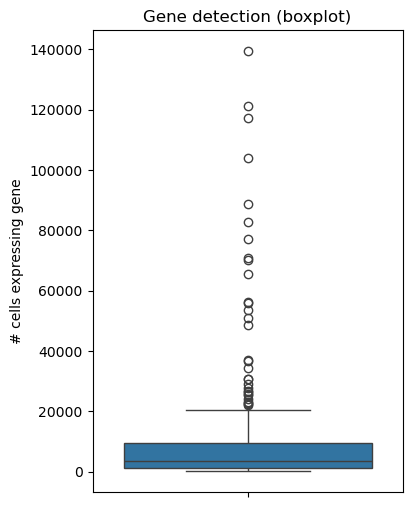

In [42]:
import seaborn as sns

plt.figure(figsize=(4, 6))
sns.boxplot(y=gene_cell_counts)

plt.ylabel("# cells expressing gene")
plt.title("Gene detection (boxplot)")

plt.show()

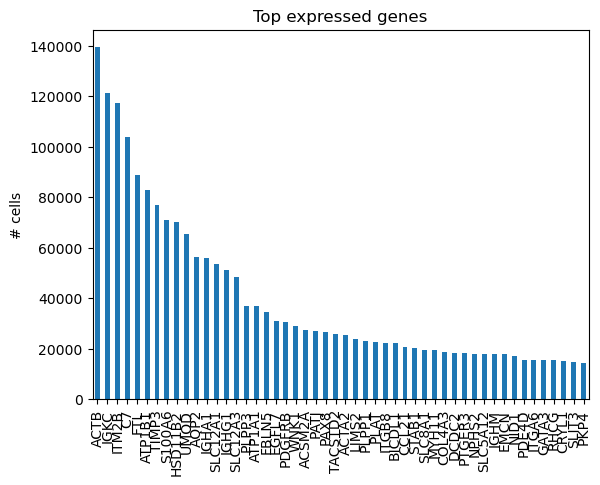

In [43]:
top_genes = pd.Series(gene_cell_counts, index=adata_subset.var_names)\
                .sort_values(ascending=False)\
                .head(50)

top_genes.plot(kind="bar")
plt.ylabel("# cells")
plt.title("Top expressed genes")
plt.show()

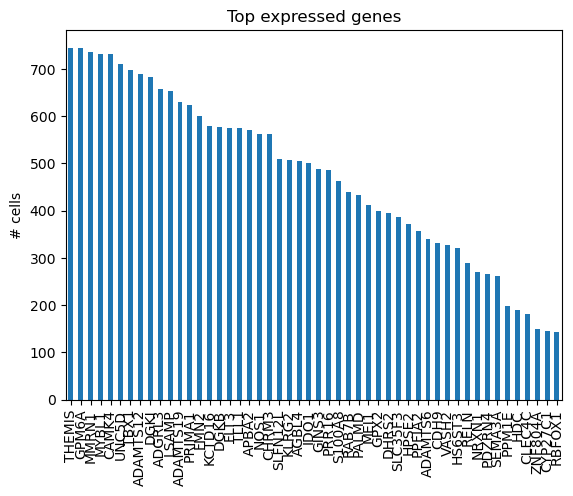

In [44]:
top_genes = pd.Series(gene_cell_counts, index=adata_subset.var_names)\
                .sort_values(ascending=False)\
                .tail(50)

top_genes.plot(kind="bar")
plt.ylabel("# cells")
plt.title("Top expressed genes")
plt.show()

2026-05-04 13:37:17 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-05-04 13:37:23 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-05-04 13:37:24 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


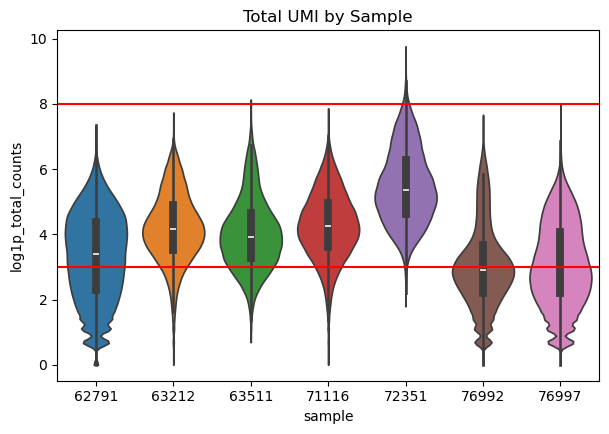

2026-05-04 13:37:57 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-05-04 13:38:02 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-05-04 13:38:03 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


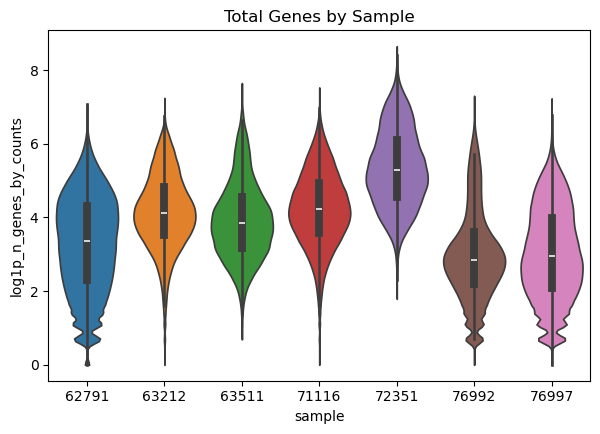

2026-05-04 13:38:27 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-05-04 13:38:32 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-05-04 13:38:32 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


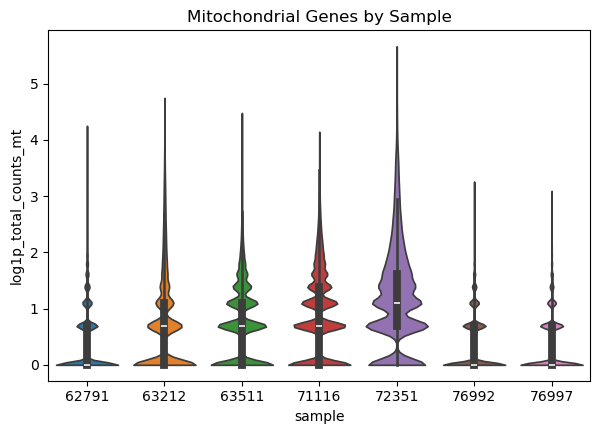

In [6]:
# Visualization for QC
sc.pl.violin(adata=adata, keys=["log1p_total_counts"], stripplot=False, inner="box",show=False, groupby="sample",)
plt.title("Total UMI by Sample")
plt.axhline(y=3, color='r', linestyle='-')
plt.axhline(y=8, color='r', linestyle='-')
plt.title("Total UMI by Sample")
plt.show()

sc.pl.violin(adata=adata, keys=["log1p_n_genes_by_counts"], groupby="sample", stripplot=False, inner="box",show=False)
plt.title("Total Genes by Sample")
plt.show()

sc.pl.violin(adata=adata, keys=["log1p_total_counts_mt"], groupby="sample", stripplot=False, inner="box",show=False)
plt.title("Mitochondrial Genes by Sample")
plt.show()

plt.close('all')

2026-04-07 11:57:24 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-04-07 11:57:27 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-04-07 11:57:28 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


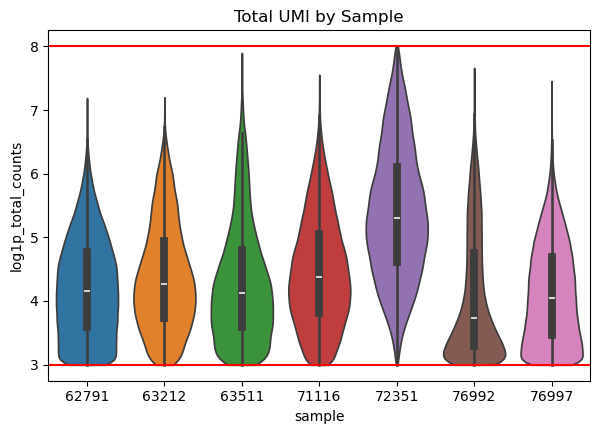

2026-04-07 11:57:36 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-04-07 11:57:40 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-04-07 11:57:40 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


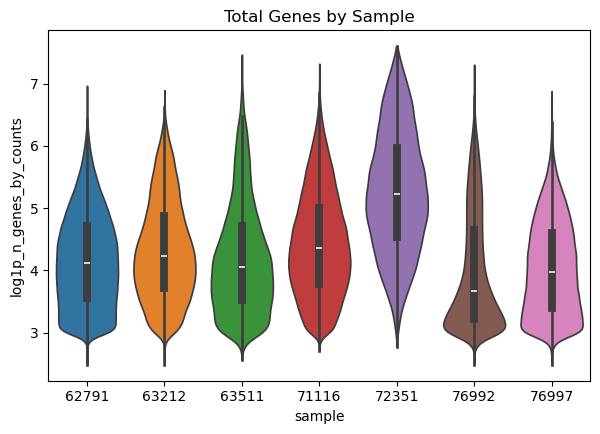

2026-04-07 11:57:49 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-04-07 11:57:53 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-04-07 11:57:53 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


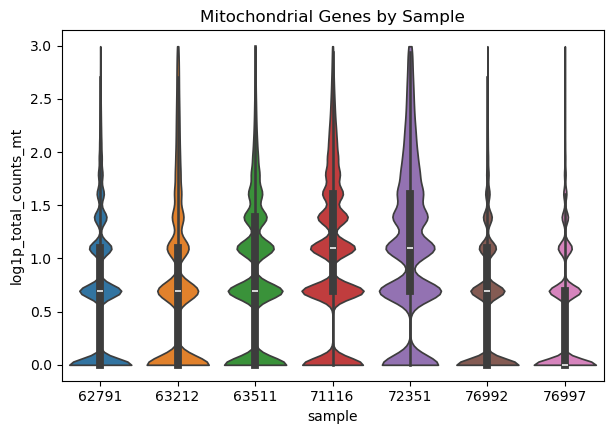

15559

In [8]:
# Estimating the cut off
min_counts = np.expm1(3).astype("int")
max_counts = np.expm1(8).astype("int")

# Filtering genes and cells
sc.pp.filter_genes(adata, min_cells=400)
sc.pp.filter_cells(adata, min_counts=min_counts)
sc.pp.filter_cells(adata, max_counts=max_counts)

adata = adata[adata.obs["log1p_total_counts_mt"] < 3, :]

# Visualization for QC
sc.pl.violin(adata=adata, keys=["log1p_total_counts"], stripplot=False, inner="box",show=False, groupby="sample",)
plt.title("Total UMI by Sample")
plt.axhline(y=3, color='r', linestyle='-')
plt.axhline(y=8, color='r', linestyle='-')
plt.title("Total UMI by Sample")
plt.show()

sc.pl.violin(adata=adata, keys=["log1p_n_genes_by_counts"], groupby="sample", stripplot=False, inner="box",show=False)
plt.title("Total Genes by Sample")
plt.show()

sc.pl.violin(adata=adata, keys=["log1p_total_counts_mt"], groupby="sample", stripplot=False, inner="box",show=False)
plt.title("Mitochondrial Genes by Sample")
plt.show()

plt.close('all')

# storing filtered counts
adata.layers["filtered_counts"] = adata.X.copy()


del max_counts, min_counts
gc.collect()

In [9]:
adata.obs

,sample,cell_id,region,x_pixel,y_pixel,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,n_counts
63511_cellid_000000001-1,63511,63511_cellid_000000001-1,63511_cell_boundaries,2288.075437,3484.848166,117,4.770685,134.0,4.905275,0.0,0.000000,0.000000,133.0
63511_cellid_000000002-1,63511,63511_cellid_000000002-1,63511_cell_boundaries,2076.487178,1813.933035,879,6.779922,1315.0,7.182352,3.0,1.386294,0.228137,1309.0
63511_cellid_000000003-1,63511,63511_cellid_000000003-1,63511_cell_boundaries,2466.581858,2585.659459,148,5.003946,176.0,5.176150,2.0,1.098612,1.136364,176.0
63511_cellid_000000005-1,63511,63511_cellid_000000005-1,63511_cell_boundaries,2350.877270,1856.848746,23,3.178054,25.0,3.258096,3.0,1.386294,12.000000,25.0
63511_cellid_000000006-1,63511,63511_cellid_000000006-1,63511_cell_boundaries,3760.766724,2499.680373,109,4.700480,123.0,4.820282,1.0,0.693147,0.813008,123.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
76997_cellid_000352505-1,76997,76997_cellid_000352505-1,76997_cell_boundaries,47999.821970,50186.691008,61,4.127134,65.0,4.189655,1.0,0.693147,1.538462,64.0
76997_cellid_000352615-1,76997,76997_cellid_000352615-1,76997_cell_boundaries,46734.990638,50176.710581,24,3.218876,24.0,3.218876,1.0,0.693147,4.166667,24.0
76997_cellid_000353017-1,76997,76997_cellid_000353017-1,76997_cell_boundaries,49039.145638,49886.874420,24,3.218876,26.0,3.295837,0.0,0.000000,0.000000,25.0
76997_cellid_000353569-1,76997,76997_cellid_000353569-1,76997_cell_boundaries,49024.063610,49989.827713,22,3.135494,26.0,3.295837,3.0,1.386294,11.538462,26.0


In [10]:
adata.var

,mt,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells
SAMD11,False,6554,0.006293,0.006273,99.428051,7211.0,8.883502,6554
NOC2L,False,6454,0.005847,0.005830,99.436778,6700.0,8.810012,6454
KLHL17,False,2882,0.002564,0.002561,99.748496,2938.0,7.985825,2882
PLEKHN1,False,613,0.000553,0.000553,99.946505,634.0,6.453625,613
HES4,False,10065,0.010539,0.010484,99.121656,12077.0,9.399141,10065
...,...,...,...,...,...,...,...,...
MT-ND4L,True,20272,0.021523,0.021294,98.230921,24663.0,10.113100,20272
MT-ND4,True,130546,0.161251,0.149498,88.607627,184779.0,12.126922,130546
MT-ND5,True,12777,0.011937,0.011867,98.884988,13679.0,9.523690,12777
MT-ND6,True,202298,0.299807,0.262216,82.346037,343551.0,12.747094,202298


### Data Normalization and Dimensionality Reduction

In [11]:
sc.pp.normalize_total(adata, target_sum = None)
sc.pp.log1p(adata)
sc.pp.scale(adata, zero_center = False)

In [12]:
rsc.tl.pca(adata, n_comps=100)

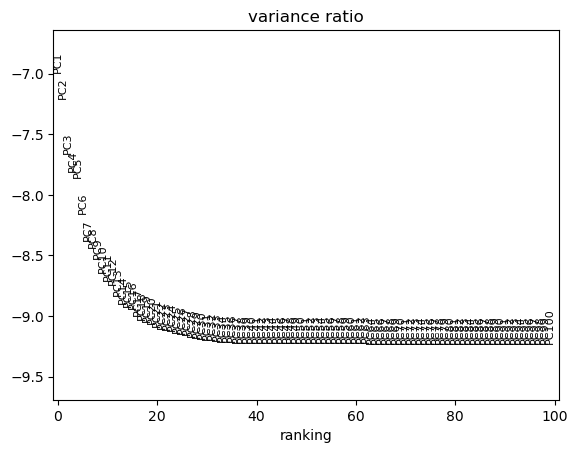

In [13]:
# adata.write("preprocessed_adata.h5ad")

# Elbow plot
sc.pl.pca_variance_ratio(adata, log=True,n_pcs=100)

### Batch Correction

In [14]:
# neighborhood and clustering resolution
RES = 0.5 # clustering resolution
NEIGHBORS = 30  # number of neighbors

MIN_DIST=0.5 #default 0.5
SPREAD=2 #default 1

# Performing batch correction
# adata_harmony = sc.read_h5ad("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/src/preprocessing/RNA/Visium_HD/analysis/zarr/adata_with_spatial_7samples.h5ad")
adata_harmony = adata.copy()

In [15]:
adata_harmony

AnnData object with n_obs × n_vars = 741742 × 13054
    obs: 'sample', 'cell_id', 'region', 'x_pixel', 'y_pixel', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_counts'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'mean', 'std'
    uns: 'spatialdata_attrs', 'sample_colors', 'log1p', 'pca'
    obsm: 'spatial', 'X_pca'
    varm: 'PCs'
    layers: 'filtered_counts'

In [16]:
rsc.pp.harmony_integrate(adata_harmony, key="sample", dtype=cp.float32)

In [17]:
# rsc.pp.neighbors(adata, n_neighbors=10, use_rep="X_pca_harmony",key_added="harmony", n_pcs=50)
#rsc.pp.neighbors(adata_harmony, n_neighbors=20, use_rep="X_pca_harmony",key_added="harmony", n_pcs=50)
#rsc.pp.neighbors(adata_harmony, n_neighbors=80, use_rep="X_pca_harmony",key_added="harmony", n_pcs=50)
rsc.pp.neighbors(adata_harmony, n_neighbors=20, use_rep="X_pca_harmony",key_added="harmony", n_pcs=30)

In [18]:
#rsc.tl.louvain(adata, resolution=0.6,neighbors_key="harmony",key_added="louvain_harmony")
#rsc.tl.leiden(adata_harmony, neighbors_key="harmony",key_added="leiden_harmony_1.2", resolution=1.2, random_state=0)
#rsc.tl.leiden(adata_harmony, neighbors_key="harmony",key_added="leiden_harmony_1.6", resolution=1.6, random_state=0)
#rsc.tl.leiden(adata_harmony, neighbors_key="harmony",key_added="leiden_harmony_1.8", resolution=1.8, random_state=0)
#rsc.tl.leiden(adata_harmony, neighbors_key="harmony",key_added="leiden_harmony_2.0", resolution=2.0, random_state=0)
#rsc.tl.leiden(adata_harmony, neighbors_key="harmony",key_added="leiden_harmony_2.5", resolution=2.5, random_state=0)
rsc.tl.leiden(adata_harmony, neighbors_key="harmony",key_added="leiden_harmony_2.2", resolution=2.2, random_state=0)

In [19]:
rsc.tl.umap(adata_harmony, neighbors_key="harmony", key_added="X_umap_harmony", min_dist=0.4, spread=2.0, random_state=0)

In [20]:
sorted(list(map(int, set(adata_harmony.obs["leiden_harmony_2.2"].tolist()))))

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29]

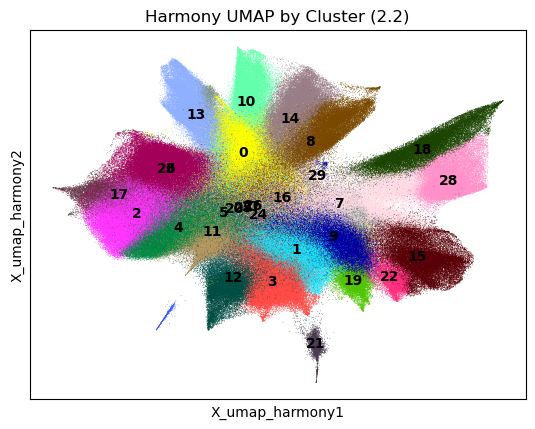

In [21]:
# min_dist=0.4, spread=2.0, n_neighbors=20, resolution=2.2, n_pcs=30
sc.pl.embedding(adata_harmony, basis="X_umap_harmony", color=["leiden_harmony_2.2"], legend_loc="on data", title=["Harmony UMAP by Cluster (2.2)"], size=1.0)

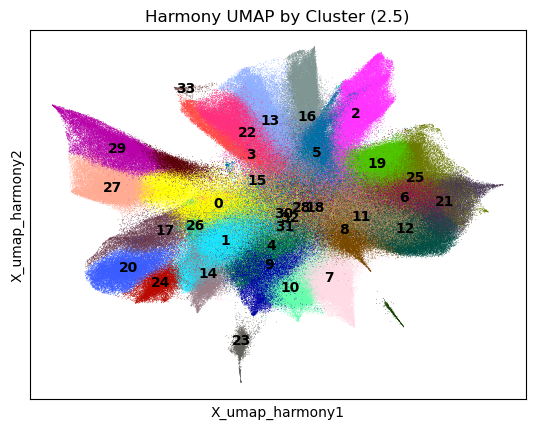

In [22]:
# min_dist=0.4, spread=2.0, n_neighbors=20, resolution=2.5, n_pcs=30
sc.pl.embedding(adata_harmony, basis="X_umap_harmony", color=["leiden_harmony_2.5"], legend_loc="on data", title=["Harmony UMAP by Cluster (2.5)"], size=1.0)

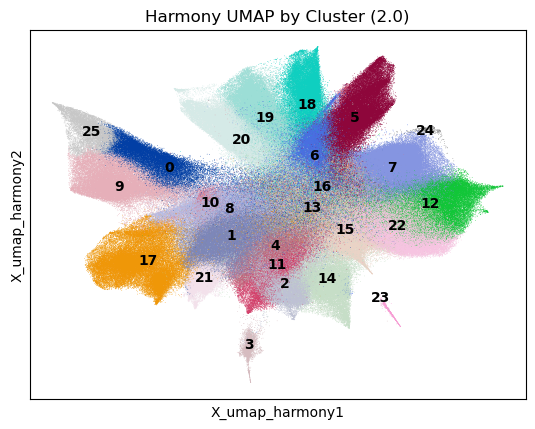

In [21]:
# min_dist=0.4, spread=2.0, n_neighbors=20, resolution=1.0, n_pcs=30
sc.pl.embedding(adata_harmony, basis="X_umap_harmony", color=["leiden_harmony_2.0"], legend_loc="on data", title=["Harmony UMAP by Cluster (2.0)"], size=1.0)

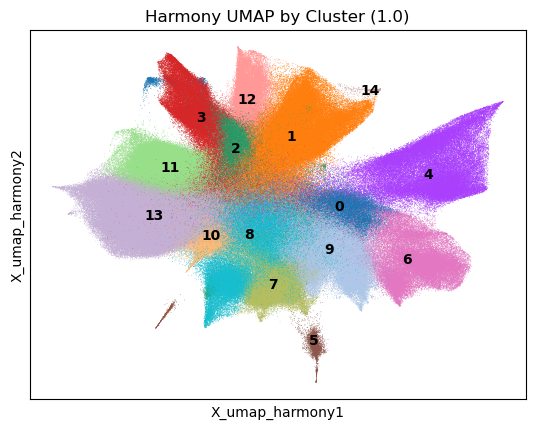

In [ ]:
# min_dist=0.4, spread=2.0, n_neighbors=20, resolution=1.0, n_pcs=30
sc.pl.embedding(adata_harmony, basis="X_umap_harmony", color=["leiden_harmony_1.0"], legend_loc="on data", title=["Harmony UMAP by Cluster (1.0)"], size=1.0)

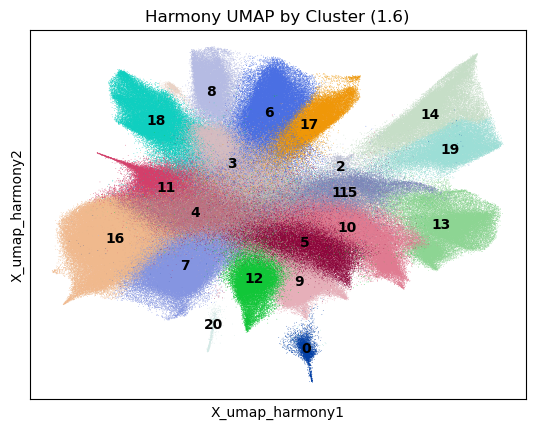

In [20]:
# min_dist=0.4, spread=2.0, n_neighbors=80, resolution=1.0, n_pcs=50
sc.pl.embedding(adata_harmony, basis="X_umap_harmony", color=["leiden_harmony_1.6"], legend_loc="on data", title=["Harmony UMAP by Cluster (1.6)"], size=1.0)

### Map the harmony cluster to spatial image

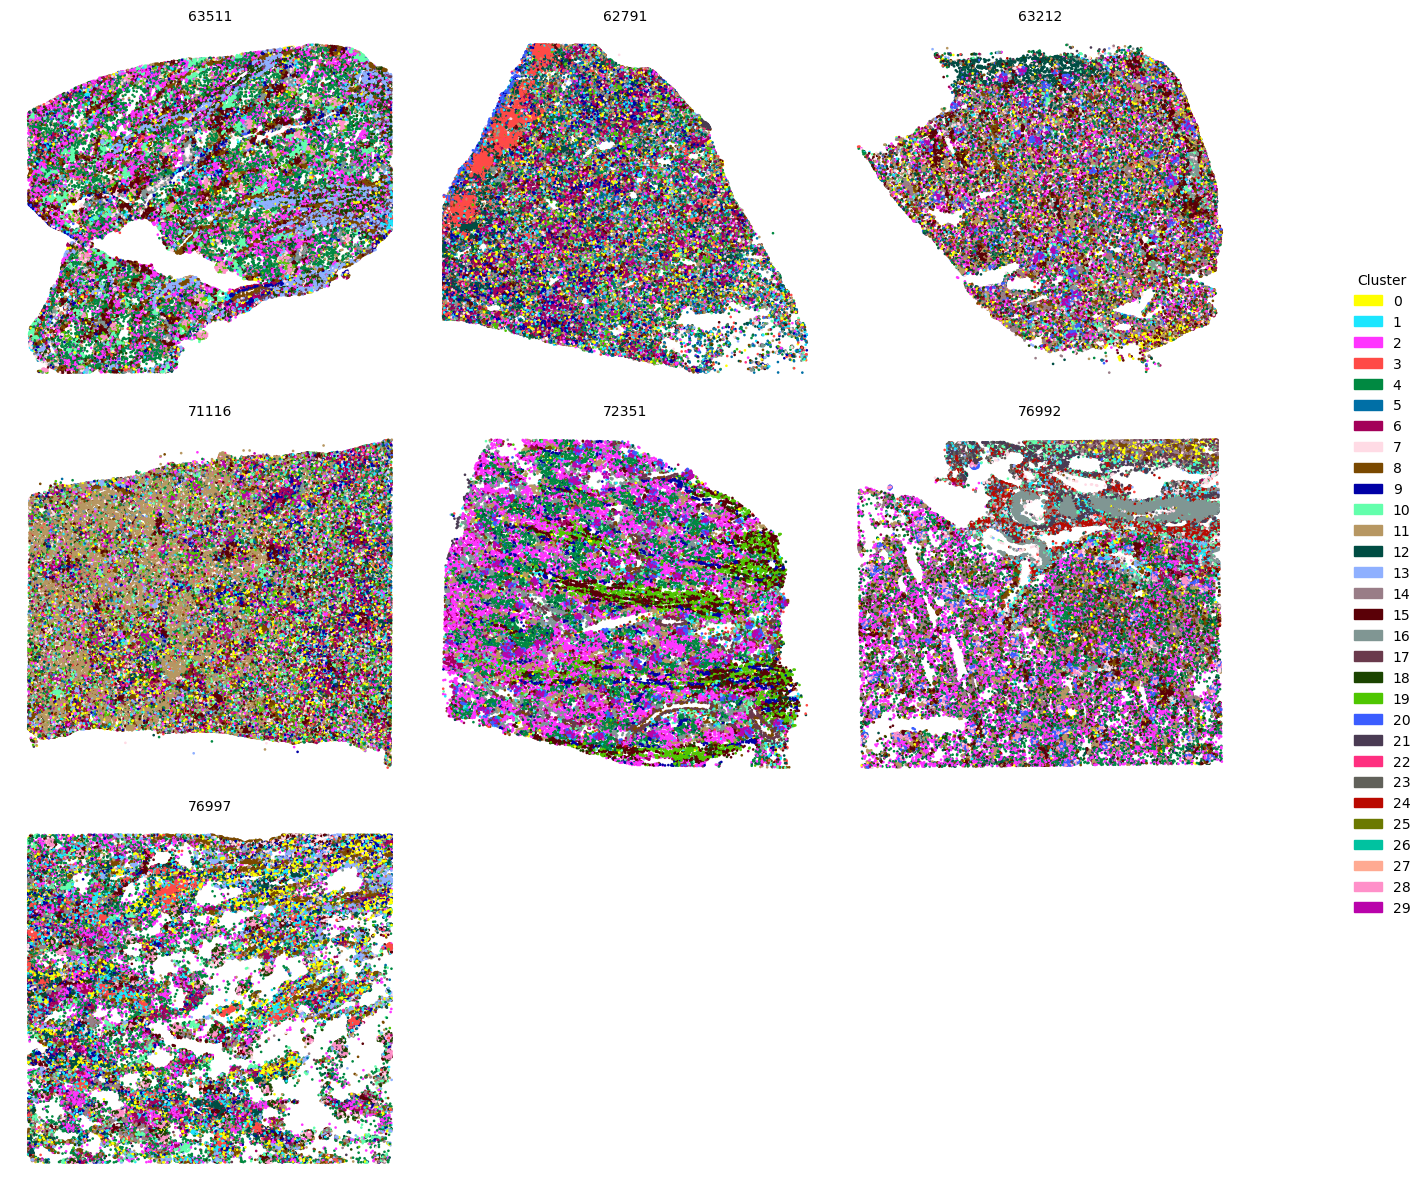

In [30]:
cluster_key = "leiden_harmony_2.2"

# be sure it is categorical
adata_harmony.obs[cluster_key] = adata_harmony.obs[cluster_key].astype("category")

# be sure the colors are in the same order as the categories
colors = adata_harmony.uns[f"{cluster_key}_colors"]
cmap = ListedColormap(colors)

samples = adata_harmony.obs["sample"].unique()

n_cols = 3
n_rows = int(np.ceil(len(samples) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(4*n_cols + 2, 4*n_rows),  # spave for legend
    squeeze=False
)

# each sample in a subplot
for i, sample in enumerate(samples):
    row = i // n_cols
    col = i % n_cols

    ax = axes[row, col]

    adata_subset = adata_harmony[adata_harmony.obs["sample"] == sample]
    clusters = adata_subset.obs[cluster_key]

    ax.scatter(
        adata_subset.obs["x_pixel"],
        adata_subset.obs["y_pixel"],
        c=clusters.cat.codes,
        cmap=cmap,
        s=0.8
    )

    ax.set_title(f"{sample}", fontsize=10)

    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_frame_on(False)
    ax.invert_yaxis()

# remove empty subplots
for j in range(len(samples), n_rows*n_cols):
    row = j // n_cols
    col = j % n_cols
    fig.delaxes(axes[row, col])

# only legend in the last subplot
categories = adata_harmony.obs[cluster_key].cat.categories

patches = [
    mpatches.Patch(color=colors[i], label=cat)
    for i, cat in enumerate(categories)
]

fig.legend(
    handles=patches,
    title="Cluster",
    loc="center right",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False
)

plt.tight_layout(rect=[0, 0, 0.9, 1]) 
plt.show()

### Save the adata

In [31]:
print(f"[{time.strftime('%Y-%m-%d %H:%M:%S', time.localtime())}] Start saving adata")
adata_harmony.write("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/src/preprocessing/RNA/Visium_HD/analysis/zarr/adata_with_spatial_7samples_with_pos_cluster2.0.h5ad", compression="gzip")

[2026-03-18 18:05:05] Start saving adata


### Calculate marker genes for each cluster

In [4]:
print(f"[{time.strftime('%Y-%m-%d %H:%M:%S', time.localtime())}] Start reading from adata")
adata_harmony = sc.read_h5ad("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/src/preprocessing/RNA/Visium_HD/analysis/zarr/adata_with_spatial_7samples_with_pos_cluster2.0.h5ad")

[2026-03-18 20:08:55] Start reading from adata


In [22]:
rsc.tl.rank_genes_groups_logreg(adata_harmony, groupby="leiden_harmony_2.2", use_raw=False)

[2026-04-07 13:15:19.414] [CUML] [warning] L-BFGS line search failed (code 3); stopping at the last valid step


In [23]:
markers = sc.get.rank_genes_groups_df(adata_harmony, None)

In [24]:
top5 = (
    markers
    .groupby("group")
    .head(5)
)

In [25]:
top5

,group,names,scores
0,0,WFDC2,0.703786
1,0,S100A2,0.552457
2,0,TACSTD2,0.524472
3,0,SLC12A1,0.496387
4,0,ITM2C,0.485708
...,...,...,...
378566,29,COL1A1,0.362613
378567,29,VIM,0.240301
378568,29,COL3A1,0.203016
378569,29,AGRN,0.197006


In [26]:
markers

,group,names,scores
0,0,WFDC2,0.703786
1,0,S100A2,0.552457
2,0,TACSTD2,0.524472
3,0,SLC12A1,0.496387
4,0,ITM2C,0.485708
...,...,...,...
391615,29,RSRP1,-0.119038
391616,29,TCP10L,-0.146786
391617,29,IGKC,-0.156421
391618,29,MT-ND6,-0.188915


In [27]:
top5_dict = (
    markers.groupby("group")["names"]
    .apply(lambda x: x.head(5).tolist())
    .to_dict()
)

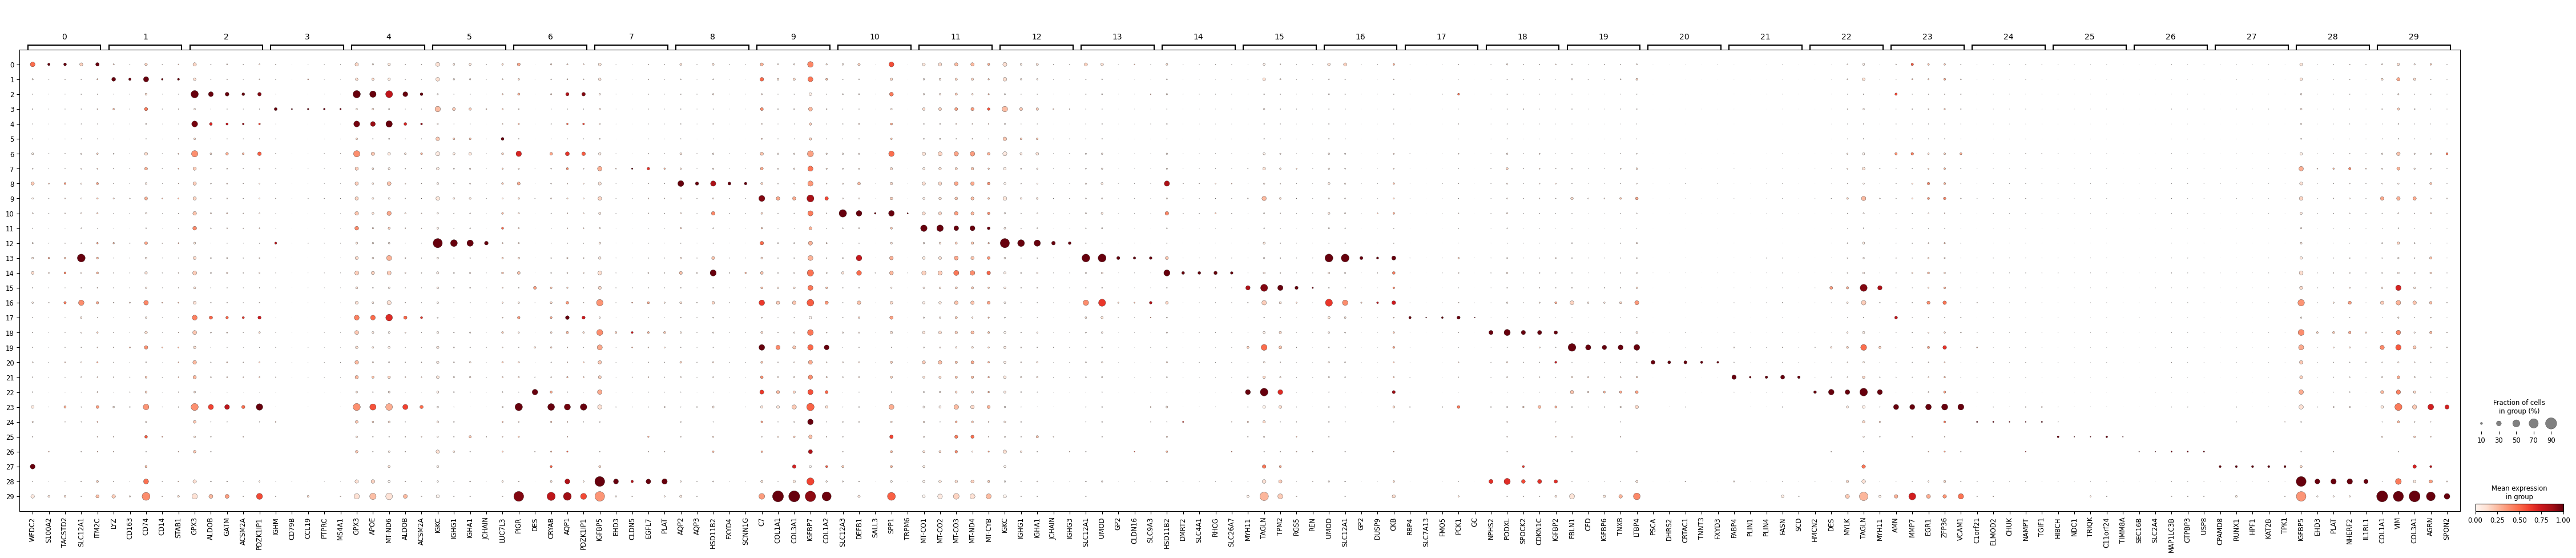

In [28]:
sc.pl.dotplot(adata_harmony, top5_dict, groupby="leiden_harmony_2.2", standard_scale="var", swap_axes=False)

### Output the marker genes to a csv file

In [29]:
markers.groupby("group").head(30).to_csv("/beegfs/data/CostaLab/Spatial_ATAC_Analysis_KuppeLab/src/preprocessing/RNA/Visium_HD/analysis/zarr/top30_markers_rsc_2.2.csv", index=False)